# UPNA Synthetic Head Pose Database - EDA

本notebook用于探索和分析UPNA合成头部姿态数据集。

## 数据集信息
- **来源**: Universidad Pública de Navarra (UPNA)
- **类型**: 合成数据集 (Synthetic)
- **用户数**: 10位用户
- **视频数**: 每位用户12个视频
- **每视频帧数**: 300帧
- **标注**: 3D头部姿态 (Tx, Ty, Tz, Roll, Yaw, Pitch) + 43个2D人脸关键点 + 边界框

## 文件结构
```
Synthetic_Head_Pose_Database_UPNA/
├── Camera_parameters.mat     # 相机参数
├── tl.mat                    # 三角化参数
├── README.txt                # 数据格式说明
└── User_XX/
    ├── head_XX.mat           # 3D模型数据
    ├── user_XX_video_YY.mp4  # 视频文件
    ├── user_XX_video_YY_groundtruth3D.txt   # 3D姿态标注
    ├── user_XX_video_YY_groundtruth2D.txt   # 2D关键点标注  
    └── user_XX_video_YY_bbox.txt            # 边界框标注
```


In [1]:
import os
import glob
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from pathlib import Path
from collections import defaultdict
import cv2
from scipy.io import loadmat

# 中文显示设置
mpl.rcParams['font.sans-serif'] = ['PingFang SC', 'Heiti SC', 'Songti SC', 'Arial Unicode MS']
mpl.rcParams['axes.unicode_minus'] = False

# 设置数据集路径 - 请根据实际情况修改
DATASET_ROOT = os.path.expanduser("~/temp/public_dataset/Synthetic_Head_Pose_Database_UPNA")

# 检查目录结构
print("=" * 60)
print("UPNA Dataset Directory Structure")
print("=" * 60)

for item in sorted(os.listdir(DATASET_ROOT)):
    item_path = os.path.join(DATASET_ROOT, item)
    if os.path.isdir(item_path):
        file_count = len([f for f in os.listdir(item_path) if os.path.isfile(os.path.join(item_path, f))])
        print(f"📁 {item}/ ({file_count} files)")
    else:
        print(f"📄 {item}")


UPNA Dataset Directory Structure
📄 Camera_parameters.mat
📄 README.txt
📁 User_01/ (49 files)
📁 User_02/ (49 files)
📁 User_03/ (49 files)
📁 User_04/ (49 files)
📁 User_05/ (49 files)
📁 User_06/ (49 files)
📁 User_07/ (49 files)
📁 User_08/ (49 files)
📁 User_09/ (49 files)
📁 User_10/ (49 files)
📄 tl.mat


## 1. 数据集统计概览


In [2]:
# 统计数据集基本信息
print("=" * 60)
print("数据集统计信息")
print("=" * 60)

# 统计用户和视频数量
user_dirs = sorted([d for d in os.listdir(DATASET_ROOT) if d.startswith("User_")])
print(f"\n用户数量: {len(user_dirs)}")

# 统计每个用户的文件
total_videos = 0
total_frames = 0
file_stats = defaultdict(int)

for user_dir in user_dirs:
    user_path = os.path.join(DATASET_ROOT, user_dir)
    files = os.listdir(user_path)
    
    # 统计视频数量
    videos = [f for f in files if f.endswith('.mp4')]
    total_videos += len(videos)
    
    # 统计各类文件
    for f in files:
        if f.endswith('.mp4'):
            file_stats['videos'] += 1
        elif f.endswith('_groundtruth3D.txt'):
            file_stats['3D_annotations'] += 1
        elif f.endswith('_groundtruth2D.txt'):
            file_stats['2D_annotations'] += 1
        elif f.endswith('_bbox.txt'):
            file_stats['bbox_files'] += 1
        elif f.endswith('.mat'):
            file_stats['mat_files'] += 1

print(f"总视频数: {total_videos}")
print(f"\n文件类型统计:")
for file_type, count in sorted(file_stats.items()):
    print(f"  {file_type}: {count}")

# 估计总帧数 (每视频300帧)
estimated_frames = total_videos * 300
print(f"\n估计总帧数: {estimated_frames} 帧 (每视频300帧)")
print(f"总样本数: {estimated_frames}")


数据集统计信息

用户数量: 10
总视频数: 120

文件类型统计:
  2D_annotations: 120
  3D_annotations: 120
  bbox_files: 120
  mat_files: 10
  videos: 120

估计总帧数: 36000 帧 (每视频300帧)
总样本数: 36000


## 2. 解析标注文件格式

### 3D Ground Truth 格式
根据README.txt，3D-groundtruth文件格式为:
- **300行** (对应300帧)
- **6列**: Tx, Ty, Tz, Roll, Yaw, Pitch
- **单位**: 平移为毫米(mm)，旋转为角度(degrees)


In [3]:
def parse_groundtruth_3d(file_path):
    """
    解析UPNA 3D ground truth文件
    
    格式: Tx, Ty, Tz, Roll, Yaw, Pitch (tab分隔)
    返回: numpy array (300, 6) - [Tx, Ty, Tz, Roll, Yaw, Pitch]
    """
    data = np.loadtxt(file_path, delimiter='\t')
    return data


def parse_groundtruth_2d(file_path):
    """
    解析UPNA 2D ground truth文件
    
    格式: x1 y1 x2 y2 ... x43 y43 (tab分隔, 86列)
    返回: numpy array (300, 43, 2) - 43个关键点的xy坐标
    """
    data = np.loadtxt(file_path, delimiter='\t')
    # reshape为 (frames, landmarks, 2)
    landmarks = data.reshape(-1, 43, 2)
    return landmarks


def parse_bbox(file_path):
    """
    解析UPNA bbox文件
    
    格式: minX minY width height (tab分隔)
    返回: numpy array (300, 4) - [x, y, w, h]
    """
    data = np.loadtxt(file_path, delimiter='\t')
    return data


# 测试解析函数
print("=" * 60)
print("测试标注文件解析")
print("=" * 60)

# 选择一个测试文件
test_user = os.path.join(DATASET_ROOT, "User_01")
test_3d_file = os.path.join(test_user, "user_01_video_01_groundtruth3D.txt")
test_2d_file = os.path.join(test_user, "user_01_video_01_groundtruth2D.txt")
test_bbox_file = os.path.join(test_user, "user_01_video_01_bbox.txt")

# 解析3D ground truth
print("\n3D Ground Truth:")
print("-" * 40)
gt_3d = parse_groundtruth_3d(test_3d_file)
print(f"Shape: {gt_3d.shape}")
print(f"前5帧数据:")
print(f"{'Frame':<6} {'Tx':>10} {'Ty':>10} {'Tz':>10} {'Roll':>10} {'Yaw':>10} {'Pitch':>10}")
for i in range(5):
    print(f"{i:<6} {gt_3d[i,0]:>10.2f} {gt_3d[i,1]:>10.2f} {gt_3d[i,2]:>10.2f} {gt_3d[i,3]:>10.4f} {gt_3d[i,4]:>10.4f} {gt_3d[i,5]:>10.4f}")

# 解析2D ground truth
print("\n2D Ground Truth (43个关键点):")
print("-" * 40)
gt_2d = parse_groundtruth_2d(test_2d_file)
print(f"Shape: {gt_2d.shape}")
print(f"第1帧前5个关键点坐标:")
for i in range(5):
    print(f"  Landmark {i+1}: ({gt_2d[0, i, 0]:.2f}, {gt_2d[0, i, 1]:.2f})")

# 解析bbox
print("\nBounding Box:")
print("-" * 40)
bbox = parse_bbox(test_bbox_file)
print(f"Shape: {bbox.shape}")
print(f"前5帧bbox: [x, y, w, h]")
for i in range(5):
    print(f"  Frame {i}: [{bbox[i,0]:.2f}, {bbox[i,1]:.2f}, {bbox[i,2]:.2f}, {bbox[i,3]:.2f}]")


测试标注文件解析

3D Ground Truth:
----------------------------------------
Shape: (300, 6)
前5帧数据:
Frame          Tx         Ty         Tz       Roll        Yaw      Pitch
0           28.72    -168.72     722.79    -2.0002     2.1025    -1.1536
1           28.72    -168.79     722.68    -1.9964     2.0994    -1.1500
2           28.90    -168.80     722.62    -1.9758     2.1013    -1.1509
3           28.83    -168.79     722.69    -1.9588     2.1018    -1.1505
4           28.95    -168.80     722.69    -1.9657     2.1028    -1.1520

2D Ground Truth (43个关键点):
----------------------------------------
Shape: (300, 43, 2)
第1帧前5个关键点坐标:
  Landmark 1: (612.72, 316.01)
  Landmark 2: (620.64, 297.99)
  Landmark 3: (638.90, 291.42)
  Landmark 4: (660.94, 291.39)
  Landmark 5: (680.73, 297.59)

Bounding Box:
----------------------------------------
Shape: (300, 4)
前5帧bbox: [x, y, w, h]
  Frame 0: [600.04, 283.96, 202.32, 222.01]
  Frame 1: [600.02, 283.85, 202.35, 222.04]
  Frame 2: [600.18, 283.84, 202.3

## 3. 收集所有姿态数据并统计


In [4]:
# 收集所有3D姿态数据
def collect_all_poses(dataset_root):
    """遍历所有3D标注文件，收集姿态数据"""
    all_data = []
    user_video_info = []
    
    user_dirs = sorted([d for d in os.listdir(dataset_root) if d.startswith("User_")])
    
    for user_dir in user_dirs:
        user_path = os.path.join(dataset_root, user_dir)
        user_num = user_dir.split('_')[1]
        
        # 找到所有3D标注文件
        gt3d_files = sorted(glob.glob(os.path.join(user_path, "*_groundtruth3D.txt")))
        
        for gt3d_file in gt3d_files:
            try:
                data = parse_groundtruth_3d(gt3d_file)
                all_data.append(data)
                
                # 提取视频编号
                video_name = os.path.basename(gt3d_file).replace("_groundtruth3D.txt", "")
                for i in range(len(data)):
                    user_video_info.append({
                        'user': user_num,
                        'video': video_name,
                        'frame': i
                    })
            except Exception as e:
                print(f"Error parsing {gt3d_file}: {e}")
    
    # 合并所有数据
    all_data = np.vstack(all_data)
    return all_data, user_video_info


print("=" * 60)
print("收集所有姿态数据")
print("=" * 60)

all_poses, video_info = collect_all_poses(DATASET_ROOT)
print(f"\n总样本数: {len(all_poses)}")
print(f"数据维度: {all_poses.shape}")

# 分离各个维度
translations = all_poses[:, :3]  # Tx, Ty, Tz
rolls = all_poses[:, 3]
yaws = all_poses[:, 4]
pitches = all_poses[:, 5]

print("\n" + "=" * 60)
print("欧拉角统计摘要")
print("=" * 60)

print(f"\nRoll (滚转角 - 歪头):")
print(f"  范围: [{rolls.min():.2f}°, {rolls.max():.2f}°]")
print(f"  均值: {rolls.mean():.2f}°")
print(f"  标准差: {rolls.std():.2f}°")

print(f"\nYaw (偏航角 - 摇头):")
print(f"  范围: [{yaws.min():.2f}°, {yaws.max():.2f}°]")
print(f"  均值: {yaws.mean():.2f}°")
print(f"  标准差: {yaws.std():.2f}°")

print(f"\nPitch (俯仰角 - 点头):")
print(f"  范围: [{pitches.min():.2f}°, {pitches.max():.2f}°]")
print(f"  均值: {pitches.mean():.2f}°")
print(f"  标准差: {pitches.std():.2f}°")

print("\n" + "-" * 60)
print("平移统计摘要 (单位: mm)")
print("-" * 60)

print(f"\nTx (水平位移):")
print(f"  范围: [{translations[:, 0].min():.2f}, {translations[:, 0].max():.2f}]")
print(f"  均值: {translations[:, 0].mean():.2f}")

print(f"\nTy (垂直位移):")
print(f"  范围: [{translations[:, 1].min():.2f}, {translations[:, 1].max():.2f}]")
print(f"  均值: {translations[:, 1].mean():.2f}")

print(f"\nTz (深度距离):")
print(f"  范围: [{translations[:, 2].min():.2f}, {translations[:, 2].max():.2f}]")
print(f"  均值: {translations[:, 2].mean():.2f}")


收集所有姿态数据

总样本数: 36000
数据维度: (36000, 6)

欧拉角统计摘要

Roll (滚转角 - 歪头):
  范围: [-46.36°, 35.84°]
  均值: -1.65°
  标准差: 7.85°

Yaw (偏航角 - 摇头):
  范围: [-42.49°, 35.80°]
  均值: 0.31°
  标准差: 8.41°

Pitch (俯仰角 - 点头):
  范围: [-30.02°, 25.58°]
  均值: -1.19°
  标准差: 5.98°

------------------------------------------------------------
平移统计摘要 (单位: mm)
------------------------------------------------------------

Tx (水平位移):
  范围: [-225.69, 210.78]
  均值: -2.26

Ty (垂直位移):
  范围: [-292.14, -71.62]
  均值: -153.32

Tz (深度距离):
  范围: [424.12, 926.60]
  均值: 680.44


## 4. 欧拉角分布可视化


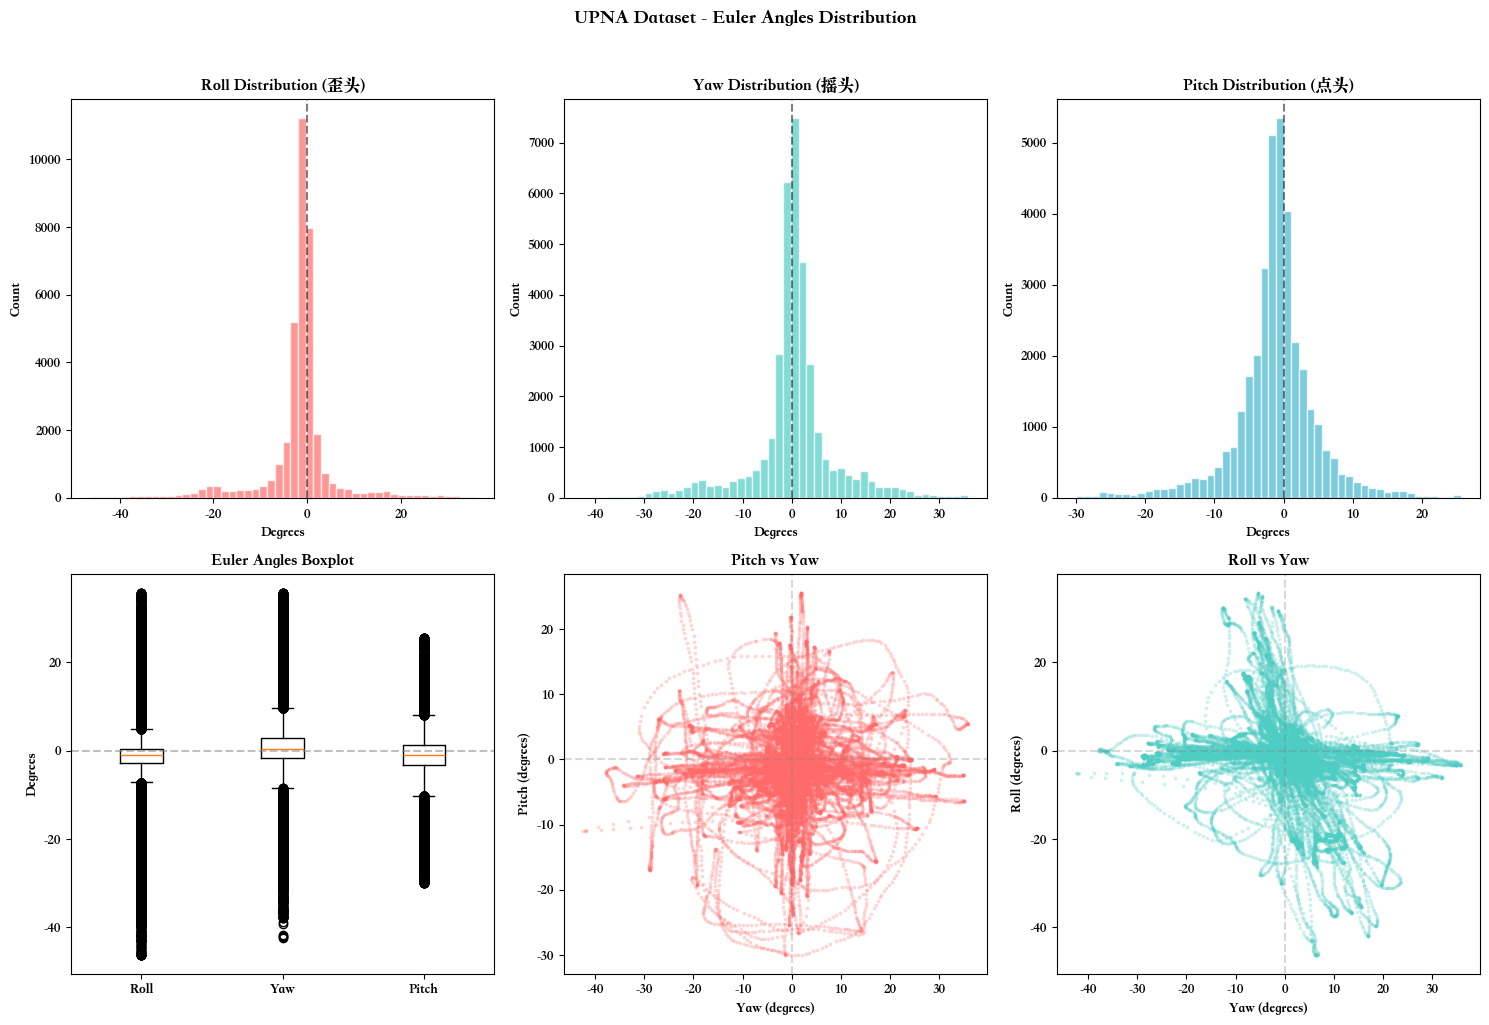


图表已保存为 upna_euler_angles_distribution.png


In [5]:
# 可视化欧拉角分布
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

# 设置颜色
colors = ['#FF6B6B', '#4ECDC4', '#45B7D1']

# 第一行：直方图
axes[0, 0].hist(rolls, bins=50, color=colors[0], alpha=0.7, edgecolor='white')
axes[0, 0].set_title('Roll Distribution (歪头)', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Degrees')
axes[0, 0].set_ylabel('Count')
axes[0, 0].axvline(x=0, color='black', linestyle='--', alpha=0.5)

axes[0, 1].hist(yaws, bins=50, color=colors[1], alpha=0.7, edgecolor='white')
axes[0, 1].set_title('Yaw Distribution (摇头)', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Degrees')
axes[0, 1].set_ylabel('Count')
axes[0, 1].axvline(x=0, color='black', linestyle='--', alpha=0.5)

axes[0, 2].hist(pitches, bins=50, color=colors[2], alpha=0.7, edgecolor='white')
axes[0, 2].set_title('Pitch Distribution (点头)', fontsize=12, fontweight='bold')
axes[0, 2].set_xlabel('Degrees')
axes[0, 2].set_ylabel('Count')
axes[0, 2].axvline(x=0, color='black', linestyle='--', alpha=0.5)

# 第二行：箱线图和2D散点图
axes[1, 0].boxplot([rolls, yaws, pitches], tick_labels=['Roll', 'Yaw', 'Pitch'])
axes[1, 0].set_title('Euler Angles Boxplot', fontsize=12, fontweight='bold')
axes[1, 0].set_ylabel('Degrees')
axes[1, 0].axhline(y=0, color='gray', linestyle='--', alpha=0.5)

# Pitch vs Yaw 散点图
axes[1, 1].scatter(yaws, pitches, alpha=0.2, s=3, c=colors[0])
axes[1, 1].set_xlabel('Yaw (degrees)')
axes[1, 1].set_ylabel('Pitch (degrees)')
axes[1, 1].set_title('Pitch vs Yaw', fontsize=12, fontweight='bold')
axes[1, 1].axhline(y=0, color='gray', linestyle='--', alpha=0.3)
axes[1, 1].axvline(x=0, color='gray', linestyle='--', alpha=0.3)

# Yaw vs Roll 散点图
axes[1, 2].scatter(yaws, rolls, alpha=0.2, s=3, c=colors[1])
axes[1, 2].set_xlabel('Yaw (degrees)')
axes[1, 2].set_ylabel('Roll (degrees)')
axes[1, 2].set_title('Roll vs Yaw', fontsize=12, fontweight='bold')
axes[1, 2].axhline(y=0, color='gray', linestyle='--', alpha=0.3)
axes[1, 2].axvline(x=0, color='gray', linestyle='--', alpha=0.3)

plt.suptitle('UPNA Dataset - Euler Angles Distribution', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('upna_euler_angles_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n图表已保存为 upna_euler_angles_distribution.png")


## 5. 按用户分析姿态分布


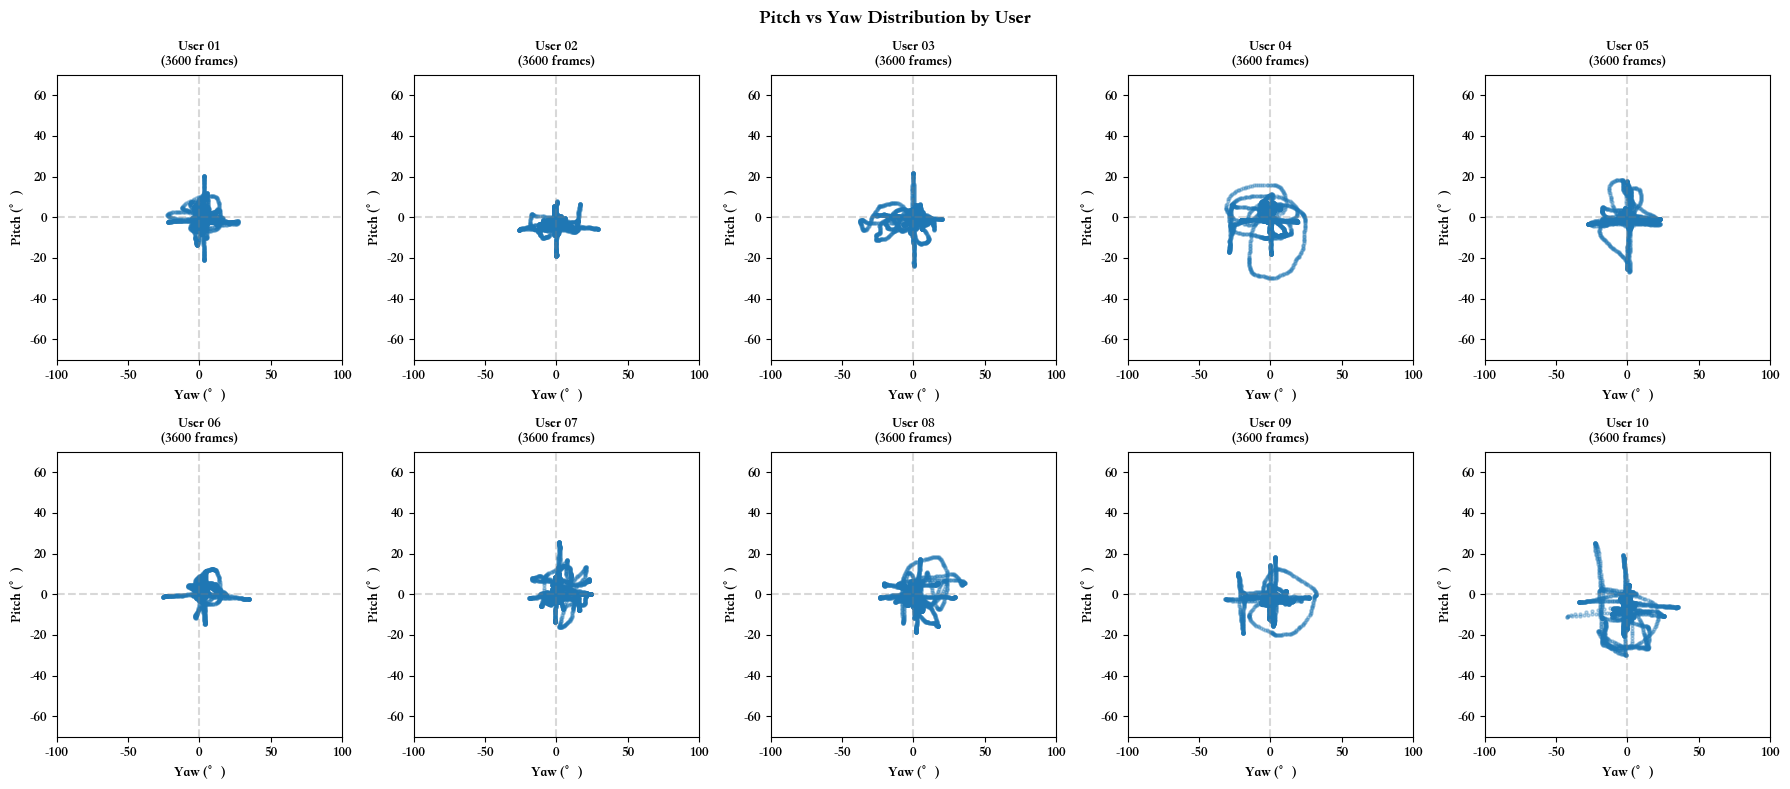


各用户姿态统计
User     Frames              Yaw Range          Pitch Range           Roll Range
--------------------------------------------------------------------------------
User 01   3600          [-22.5°, 27.2°]      [-20.9°, 20.3°]      [-36.7°, 21.8°]
User 02   3600          [-26.1°, 29.2°]       [-19.2°, 7.8°]      [-25.4°, 32.5°]
User 03   3600          [-37.8°, 20.0°]      [-23.8°, 21.9°]      [-25.5°, 22.3°]
User 04   3600          [-31.1°, 24.1°]      [-30.0°, 15.9°]      [-46.4°, 29.3°]
User 05   3600          [-27.8°, 22.9°]      [-26.7°, 18.4°]      [-28.2°, 24.6°]
User 06   3600          [-25.8°, 34.9°]      [-14.4°, 12.6°]      [-39.7°, 34.5°]
User 07   3600          [-18.9°, 24.3°]      [-16.3°, 25.6°]      [-30.4°, 17.6°]
User 08   3600          [-23.8°, 35.8°]      [-18.5°, 18.3°]      [-42.0°, 31.8°]
User 09   3600          [-31.6°, 32.1°]      [-20.0°, 18.2°]      [-35.4°, 35.8°]
User 10   3600          [-42.5°, 35.1°]      [-30.0°, 25.2°]      [-43.1°, 35.0°]


In [6]:
# 按用户统计姿态分布
def collect_poses_by_user(dataset_root):
    """收集每个用户的姿态数据"""
    user_poses = {}
    user_dirs = sorted([d for d in os.listdir(dataset_root) if d.startswith("User_")])
    
    for user_dir in user_dirs:
        user_path = os.path.join(dataset_root, user_dir)
        user_num = user_dir.split('_')[1]
        
        user_data = []
        gt3d_files = sorted(glob.glob(os.path.join(user_path, "*_groundtruth3D.txt")))
        
        for gt3d_file in gt3d_files:
            try:
                data = parse_groundtruth_3d(gt3d_file)
                user_data.append(data)
            except:
                pass
        
        if user_data:
            user_poses[user_num] = np.vstack(user_data)
    
    return user_poses


user_poses = collect_poses_by_user(DATASET_ROOT)

# 可视化每个用户的Yaw分布
fig, axes = plt.subplots(2, 5, figsize=(18, 8))
axes = axes.flatten()

for idx, (user_id, poses) in enumerate(sorted(user_poses.items())):
    user_yaws = poses[:, 4]  # Yaw
    user_pitches = poses[:, 5]  # Pitch
    
    axes[idx].scatter(user_yaws, user_pitches, alpha=0.3, s=5)
    axes[idx].set_title(f'User {user_id}\n({len(poses)} frames)', fontsize=10)
    axes[idx].set_xlabel('Yaw (°)')
    axes[idx].set_ylabel('Pitch (°)')
    axes[idx].axhline(y=0, color='gray', linestyle='--', alpha=0.3)
    axes[idx].axvline(x=0, color='gray', linestyle='--', alpha=0.3)
    axes[idx].set_xlim(-100, 100)
    axes[idx].set_ylim(-70, 70)

plt.suptitle('Pitch vs Yaw Distribution by User', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('upna_user_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

# 打印每个用户的统计信息
print("\n" + "=" * 80)
print("各用户姿态统计")
print("=" * 80)
print(f"{'User':<8} {'Frames':<8} {'Yaw Range':>20} {'Pitch Range':>20} {'Roll Range':>20}")
print("-" * 80)

for user_id, poses in sorted(user_poses.items()):
    yaw_range = f"[{poses[:, 4].min():.1f}°, {poses[:, 4].max():.1f}°]"
    pitch_range = f"[{poses[:, 5].min():.1f}°, {poses[:, 5].max():.1f}°]"
    roll_range = f"[{poses[:, 3].min():.1f}°, {poses[:, 3].max():.1f}°]"
    print(f"User {user_id:<4} {len(poses):<8} {yaw_range:>20} {pitch_range:>20} {roll_range:>20}")


## 6. 视频帧采样与关键点可视化


采样视频帧并可视化关键点


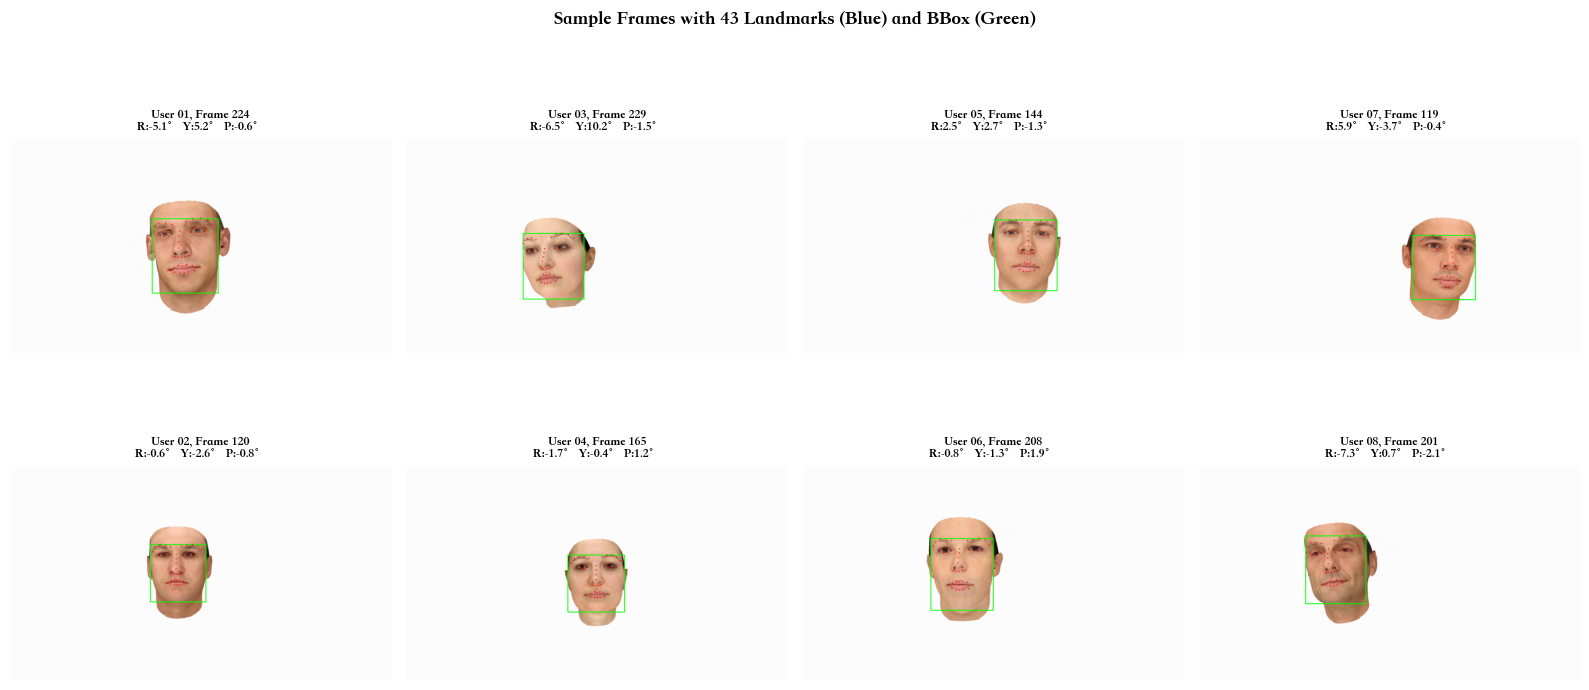


成功可视化 8 个样本


In [7]:
def extract_frame_from_video(video_path, frame_idx):
    """从视频中提取指定帧"""
    cap = cv2.VideoCapture(video_path)
    cap.set(cv2.CAP_PROP_POS_FRAMES, frame_idx)
    ret, frame = cap.read()
    cap.release()
    if ret:
        return cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    return None


def draw_landmarks_on_frame(frame, landmarks, bbox=None):
    """在帧上绘制关键点和边界框"""
    frame_draw = frame.copy()
    
    # 绘制边界框
    if bbox is not None:
        x, y, w, h = int(bbox[0]), int(bbox[1]), int(bbox[2]), int(bbox[3])
        cv2.rectangle(frame_draw, (x, y), (x+w, y+h), (0, 255, 0), 2)
    
    # 绘制关键点
    for i, (x, y) in enumerate(landmarks):
        cv2.circle(frame_draw, (int(x), int(y)), 2, (255, 0, 0), -1)
    
    return frame_draw


# 从不同用户采样视频帧
print("=" * 60)
print("采样视频帧并可视化关键点")
print("=" * 60)

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

sample_count = 0
for user_num in ['01', '03', '05', '07', '02', '04', '06', '08']:
    if sample_count >= 8:
        break
        
    user_path = os.path.join(DATASET_ROOT, f"User_{user_num}")
    if not os.path.exists(user_path):
        continue
    
    # 选择一个视频
    video_files = sorted(glob.glob(os.path.join(user_path, "*.mp4")))
    if not video_files:
        continue
    
    video_path = video_files[0]
    video_name = os.path.basename(video_path).replace('.mp4', '')
    
    # 加载对应的标注
    gt2d_path = os.path.join(user_path, f"{video_name}_groundtruth2D.txt")
    gt3d_path = os.path.join(user_path, f"{video_name}_groundtruth3D.txt")
    bbox_path = os.path.join(user_path, f"{video_name}_bbox.txt")
    
    if not all(os.path.exists(p) for p in [gt2d_path, gt3d_path, bbox_path]):
        continue
    
    try:
        landmarks_2d = parse_groundtruth_2d(gt2d_path)
        poses_3d = parse_groundtruth_3d(gt3d_path)
        bboxes = parse_bbox(bbox_path)
        
        # 随机选择一帧
        frame_idx = np.random.randint(50, 250)
        frame = extract_frame_from_video(video_path, frame_idx)
        
        if frame is not None:
            # 绘制关键点和边界框
            frame_with_landmarks = draw_landmarks_on_frame(
                frame, 
                landmarks_2d[frame_idx], 
                bboxes[frame_idx]
            )
            
            # 获取姿态信息
            pose = poses_3d[frame_idx]
            roll, yaw, pitch = pose[3], pose[4], pose[5]
            
            axes[sample_count].imshow(frame_with_landmarks)
            axes[sample_count].set_title(
                f'User {user_num}, Frame {frame_idx}\n'
                f'R:{roll:.1f}° Y:{yaw:.1f}° P:{pitch:.1f}°',
                fontsize=9
            )
            axes[sample_count].axis('off')
            sample_count += 1
    except Exception as e:
        print(f"Error processing User {user_num}: {e}")

# 隐藏多余子图
for idx in range(sample_count, 8):
    axes[idx].axis('off')

plt.suptitle('Sample Frames with 43 Landmarks (Blue) and BBox (Green)', 
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('upna_sample_frames.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"\n成功可视化 {sample_count} 个样本")


## 7. 不同姿态范围的样本展示

展示不同Yaw角度范围的样本，验证数据集覆盖的姿态多样性。


不同Yaw角度范围的样本展示


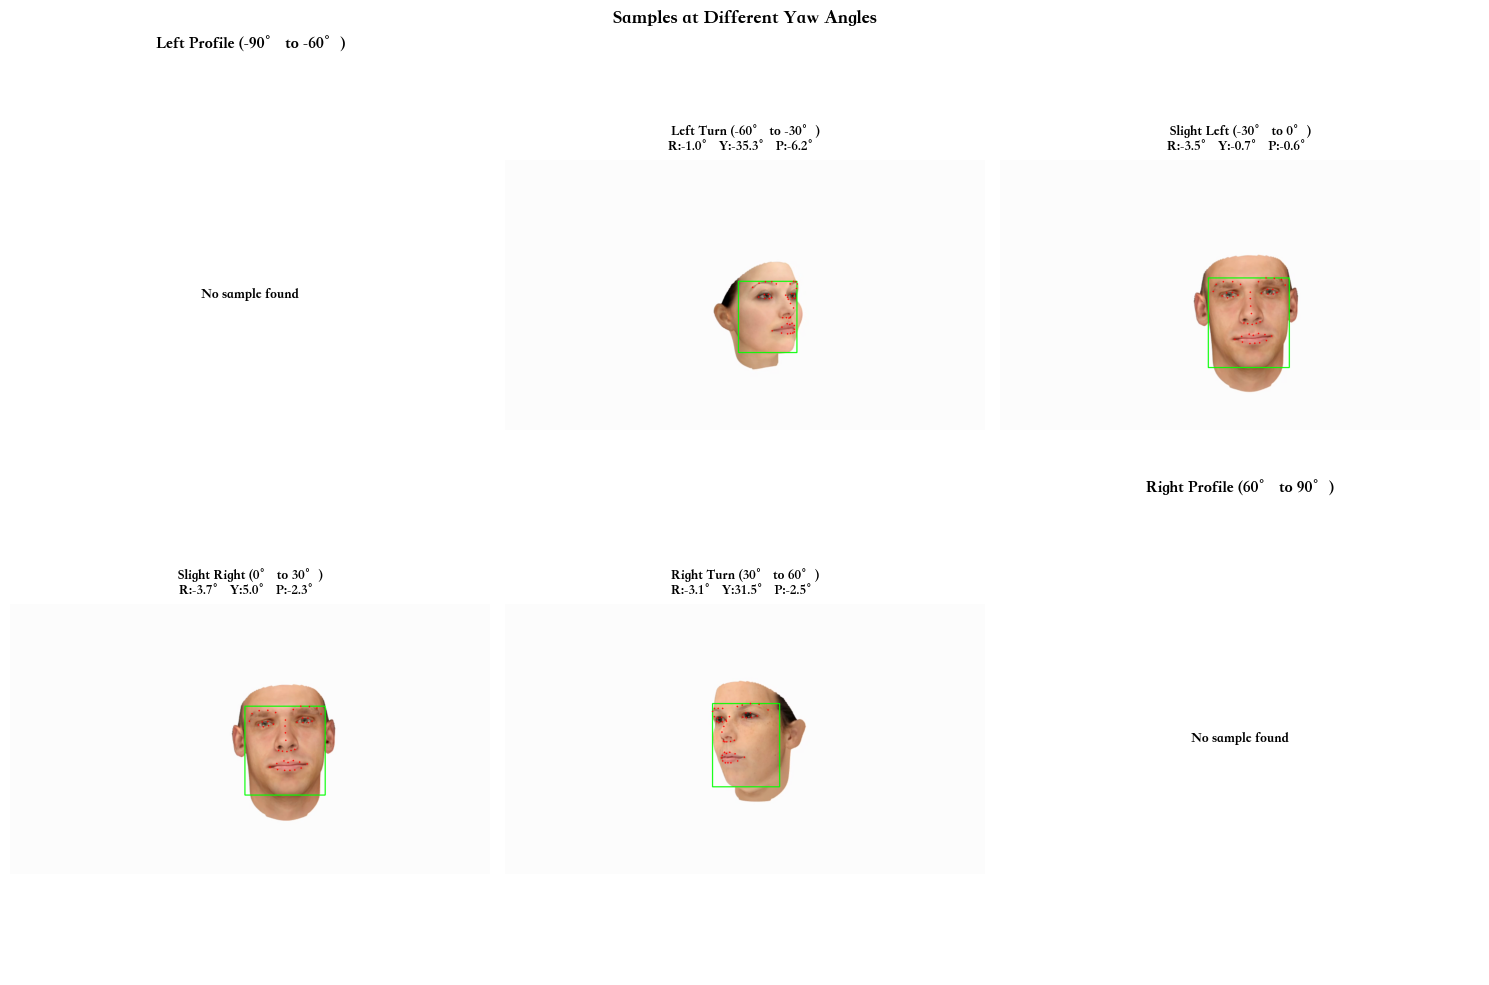

In [8]:
# 按Yaw角度范围采样
def find_samples_by_yaw_range(dataset_root, yaw_min, yaw_max, max_samples=3):
    """找到指定Yaw范围内的样本"""
    samples = []
    user_dirs = sorted([d for d in os.listdir(dataset_root) if d.startswith("User_")])
    
    for user_dir in user_dirs:
        if len(samples) >= max_samples:
            break
            
        user_path = os.path.join(dataset_root, user_dir)
        gt3d_files = sorted(glob.glob(os.path.join(user_path, "*_groundtruth3D.txt")))
        
        for gt3d_file in gt3d_files:
            if len(samples) >= max_samples:
                break
                
            try:
                poses = parse_groundtruth_3d(gt3d_file)
                video_name = os.path.basename(gt3d_file).replace("_groundtruth3D.txt", "")
                video_path = os.path.join(user_path, f"{video_name}.mp4")
                gt2d_path = os.path.join(user_path, f"{video_name}_groundtruth2D.txt")
                bbox_path = os.path.join(user_path, f"{video_name}_bbox.txt")
                
                if not all(os.path.exists(p) for p in [video_path, gt2d_path, bbox_path]):
                    continue
                
                # 找到符合条件的帧
                yaws = poses[:, 4]
                valid_frames = np.where((yaws >= yaw_min) & (yaws <= yaw_max))[0]
                
                if len(valid_frames) > 0:
                    frame_idx = np.random.choice(valid_frames)
                    samples.append({
                        'video_path': video_path,
                        'gt2d_path': gt2d_path,
                        'bbox_path': bbox_path,
                        'frame_idx': frame_idx,
                        'pose': poses[frame_idx],
                        'user': user_dir
                    })
            except:
                pass
    
    return samples


# 定义不同的Yaw范围
yaw_ranges = [
    (-90, -60, "Left Profile (-90° to -60°)"),
    (-60, -30, "Left Turn (-60° to -30°)"),
    (-30, 0, "Slight Left (-30° to 0°)"),
    (0, 30, "Slight Right (0° to 30°)"),
    (30, 60, "Right Turn (30° to 60°)"),
    (60, 90, "Right Profile (60° to 90°)")
]

print("=" * 60)
print("不同Yaw角度范围的样本展示")
print("=" * 60)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

np.random.seed(42)

for idx, (yaw_min, yaw_max, title) in enumerate(yaw_ranges):
    samples = find_samples_by_yaw_range(DATASET_ROOT, yaw_min, yaw_max, max_samples=1)
    
    if samples:
        sample = samples[0]
        try:
            frame = extract_frame_from_video(sample['video_path'], sample['frame_idx'])
            landmarks = parse_groundtruth_2d(sample['gt2d_path'])[sample['frame_idx']]
            bbox = parse_bbox(sample['bbox_path'])[sample['frame_idx']]
            
            if frame is not None:
                frame_with_landmarks = draw_landmarks_on_frame(frame, landmarks, bbox)
                pose = sample['pose']
                
                axes[idx].imshow(frame_with_landmarks)
                axes[idx].set_title(
                    f'{title}\n'
                    f'R:{pose[3]:.1f}° Y:{pose[4]:.1f}° P:{pose[5]:.1f}°',
                    fontsize=10
                )
                axes[idx].axis('off')
            else:
                axes[idx].text(0.5, 0.5, 'Frame not available', ha='center', va='center')
                axes[idx].set_title(title)
                axes[idx].axis('off')
        except Exception as e:
            axes[idx].text(0.5, 0.5, f'Error: {e}', ha='center', va='center')
            axes[idx].set_title(title)
            axes[idx].axis('off')
    else:
        axes[idx].text(0.5, 0.5, 'No sample found', ha='center', va='center')
        axes[idx].set_title(title)
        axes[idx].axis('off')

plt.suptitle('Samples at Different Yaw Angles', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('upna_yaw_samples.png', dpi=150, bbox_inches='tight')
plt.show()


## 8. 关键点可视化验证 (43点布局)


43个关键点详细可视化


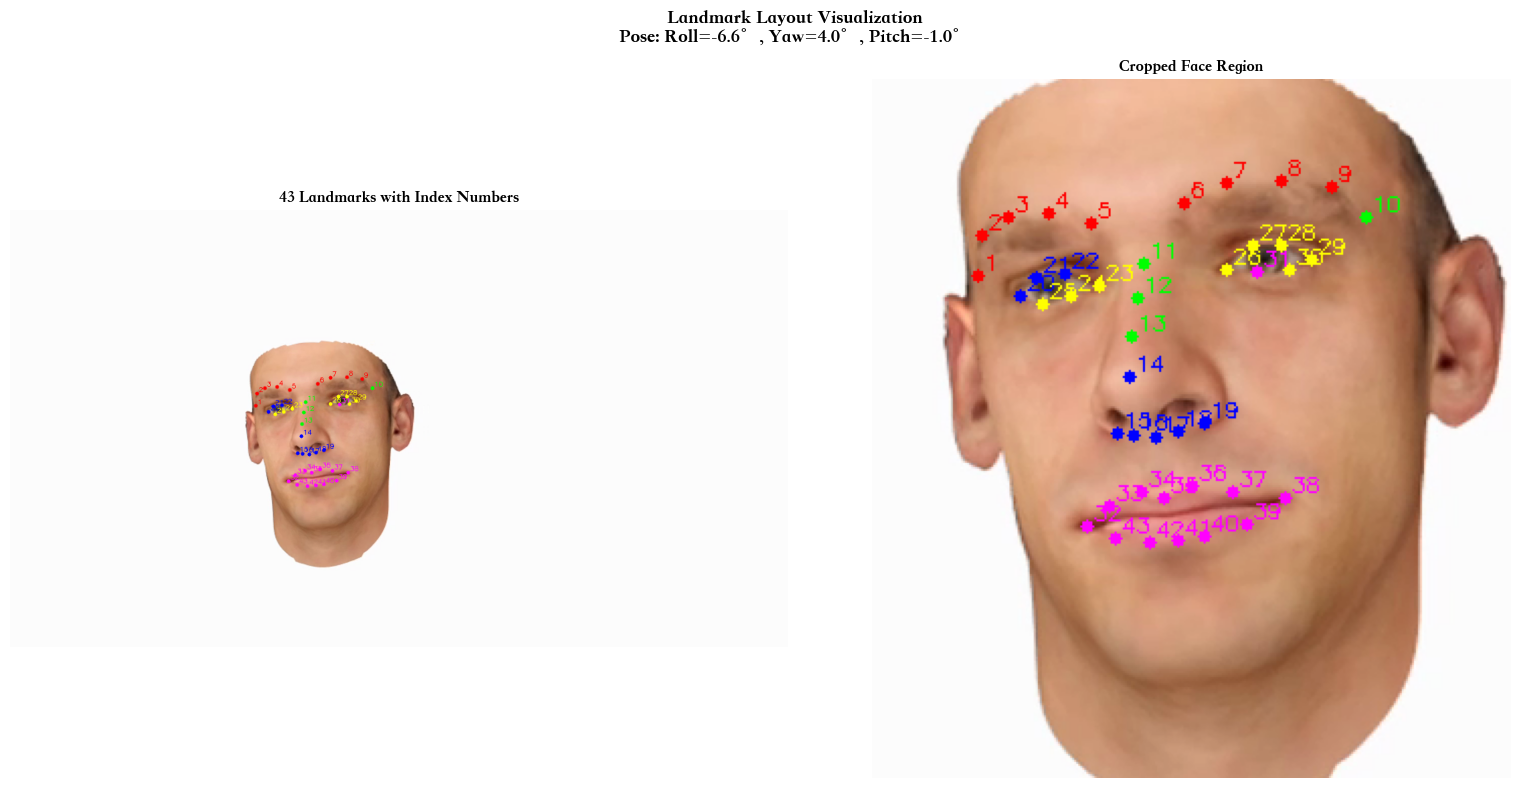


关键点颜色说明:
  🔴 红色 (1-9): 脸部轮廓
  🟢 绿色 (10-13): 眉毛
  🔵 蓝色 (14-22): 鼻子
  🟡 黄色 (23-30): 眼睛
  🟣 紫色 (31-43): 嘴巴


In [9]:
# 展示43个关键点的详细布局
# 根据README: 43个关键点是iBUG 68点的子集

def draw_numbered_landmarks(frame, landmarks, fontScale=0.35):
    """绘制带编号的关键点"""
    frame_draw = frame.copy()
    
    # 定义不同区域的颜色
    colors = {
        'face_contour': (255, 0, 0),      # 红色 - 脸部轮廓
        'eyebrow': (0, 255, 0),           # 绿色 - 眉毛
        'nose': (0, 0, 255),              # 蓝色 - 鼻子
        'eye': (255, 255, 0),             # 黄色 - 眼睛
        'mouth': (255, 0, 255)            # 紫色 - 嘴巴
    }
    
    for i, (x, y) in enumerate(landmarks):
        x, y = int(x), int(y)
        
        # 根据索引判断区域 (这是一个估计，需要根据实际数据调整)
        if i < 9:
            color = colors['face_contour']
        elif i < 13:
            color = colors['eyebrow']
        elif i < 22:
            color = colors['nose']
        elif i < 30:
            color = colors['eye']
        else:
            color = colors['mouth']
        
        cv2.circle(frame_draw, (x, y), 3, color, -1)
        cv2.putText(frame_draw, str(i+1), (x+3, y-3), 
                    cv2.FONT_HERSHEY_SIMPLEX, fontScale, color, 1)
    
    return frame_draw


# 选择一个正面样本进行详细可视化
print("=" * 60)
print("43个关键点详细可视化")
print("=" * 60)

# 找一个接近正面的样本
frontal_samples = find_samples_by_yaw_range(DATASET_ROOT, -10, 10, max_samples=1)

if frontal_samples:
    sample = frontal_samples[0]
    
    try:
        frame = extract_frame_from_video(sample['video_path'], sample['frame_idx'])
        landmarks = parse_groundtruth_2d(sample['gt2d_path'])[sample['frame_idx']]
        bbox = parse_bbox(sample['bbox_path'])[sample['frame_idx']]
        
        if frame is not None:
            fig, axes = plt.subplots(1, 2, figsize=(16, 8))
            
            # 左图：带编号的关键点
            frame_numbered = draw_numbered_landmarks(frame, landmarks)
            axes[0].imshow(frame_numbered)
            axes[0].set_title('43 Landmarks with Index Numbers', fontsize=12, fontweight='bold')
            axes[0].axis('off')
            
            # 右图：裁剪后的人脸区域
            x, y, w, h = int(bbox[0]), int(bbox[1]), int(bbox[2]), int(bbox[3])
            padding = 50
            x1 = max(0, x - padding)
            y1 = max(0, y - padding)
            x2 = min(frame.shape[1], x + w + padding)
            y2 = min(frame.shape[0], y + h + padding)
            
            cropped = frame_numbered[y1:y2, x1:x2]
            axes[1].imshow(cropped)
            axes[1].set_title('Cropped Face Region', fontsize=12, fontweight='bold')
            axes[1].axis('off')
            
            plt.suptitle(
                f'Landmark Layout Visualization\n'
                f'Pose: Roll={sample["pose"][3]:.1f}°, Yaw={sample["pose"][4]:.1f}°, Pitch={sample["pose"][5]:.1f}°',
                fontsize=14, fontweight='bold'
            )
            plt.tight_layout()
            plt.savefig('upna_landmarks_layout.png', dpi=150, bbox_inches='tight')
            plt.show()
            
            print("\n关键点颜色说明:")
            print("  🔴 红色 (1-9): 脸部轮廓")
            print("  🟢 绿色 (10-13): 眉毛")
            print("  🔵 蓝色 (14-22): 鼻子")
            print("  🟡 黄色 (23-30): 眼睛")
            print("  🟣 紫色 (31-43): 嘴巴")
    except Exception as e:
        print(f"Error: {e}")
else:
    print("未找到正面样本")


## 9. 数据质量检查与总结


In [10]:
# 数据质量检查
print("=" * 70)
print("UPNA Dataset Summary Report")
print("=" * 70)

# 基本统计
print("\n📊 基本统计:")
print("-" * 70)
print(f"  总用户数: {len(user_dirs)}")
print(f"  总视频数: {total_videos}")
print(f"  总样本数: {len(all_poses)} 帧")

# 欧拉角覆盖范围
print("\n📐 欧拉角覆盖范围:")
print("-" * 70)
print(f"  Roll (歪头):  [{rolls.min():.1f}°, {rolls.max():.1f}°]  (range: {rolls.max()-rolls.min():.1f}°)")
print(f"  Yaw (摇头):   [{yaws.min():.1f}°, {yaws.max():.1f}°]  (range: {yaws.max()-yaws.min():.1f}°)")
print(f"  Pitch (点头): [{pitches.min():.1f}°, {pitches.max():.1f}°]  (range: {pitches.max()-pitches.min():.1f}°)")

# 异常值检查
print("\n⚠️ 异常值检查 (|angle| > 90°):")
print("-" * 70)
roll_outliers = np.sum(np.abs(rolls) > 90)
yaw_outliers = np.sum(np.abs(yaws) > 90)
pitch_outliers = np.sum(np.abs(pitches) > 90)
print(f"  Roll 异常值: {roll_outliers} ({100*roll_outliers/len(rolls):.2f}%)")
print(f"  Yaw 异常值: {yaw_outliers} ({100*yaw_outliers/len(yaws):.2f}%)")
print(f"  Pitch 异常值: {pitch_outliers} ({100*pitch_outliers/len(pitches):.2f}%)")

# 数据完整性
print("\n✅ 数据完整性检查:")
print("-" * 70)
missing_files = []
for user_dir in user_dirs:
    user_path = os.path.join(DATASET_ROOT, user_dir)
    videos = sorted(glob.glob(os.path.join(user_path, "*.mp4")))
    
    for video_path in videos:
        video_name = os.path.basename(video_path).replace('.mp4', '')
        required_files = [
            f"{video_name}_groundtruth3D.txt",
            f"{video_name}_groundtruth2D.txt",
            f"{video_name}_bbox.txt"
        ]
        
        for req_file in required_files:
            if not os.path.exists(os.path.join(user_path, req_file)):
                missing_files.append(os.path.join(user_dir, req_file))

if missing_files:
    print(f"  缺失文件数: {len(missing_files)}")
    for mf in missing_files[:5]:
        print(f"    - {mf}")
    if len(missing_files) > 5:
        print(f"    ... 以及 {len(missing_files)-5} 个其他文件")
else:
    print("  ✅ 所有标注文件完整!")

# 与其他数据集对比
print("\n📈 与其他头部姿态数据集对比:")
print("-" * 70)
print(f"  {'Dataset':<20} {'Samples':>12} {'Yaw Range':>20} {'Type':>15}")
print(f"  {'-'*20} {'-'*12} {'-'*20} {'-'*15}")
print(f"  {'UPNA':<20} {len(all_poses):>12,} {f'[{yaws.min():.0f}°, {yaws.max():.0f}°]':>20} {'Synthetic':>15}")
print(f"  {'BIWI':<20} {'~15,000':>12} {'[-75°, +75°]':>20} {'Real (Kinect)':>15}")
print(f"  {'AFLW2000-3D':<20} {'~2,000':>12} {'[-90°, +90°]':>20} {'Real (Wild)':>15}")
print(f"  {'300W-LP':<20} {'~61,000':>12} {'[-90°, +90°]':>20} {'Synthetic':>15}")

# 数据集特点总结
print("\n💡 数据集特点:")
print("-" * 70)
print("""
  1. 合成数据集，标注精确
  2. 包含43个人脸关键点 (iBUG 68点子集)
  3. 提供3D平移和旋转的完整标注
  4. 每个视频300帧，共120个视频
  5. 适合用于头部姿态估计模型的训练和评估
""")

print("=" * 70)
print("EDA 完成!")
print("=" * 70)


UPNA Dataset Summary Report

📊 基本统计:
----------------------------------------------------------------------
  总用户数: 10
  总视频数: 120
  总样本数: 36000 帧

📐 欧拉角覆盖范围:
----------------------------------------------------------------------
  Roll (歪头):  [-46.4°, 35.8°]  (range: 82.2°)
  Yaw (摇头):   [-42.5°, 35.8°]  (range: 78.3°)
  Pitch (点头): [-30.0°, 25.6°]  (range: 55.6°)

⚠️ 异常值检查 (|angle| > 90°):
----------------------------------------------------------------------
  Roll 异常值: 0 (0.00%)
  Yaw 异常值: 0 (0.00%)
  Pitch 异常值: 0 (0.00%)

✅ 数据完整性检查:
----------------------------------------------------------------------
  ✅ 所有标注文件完整!

📈 与其他头部姿态数据集对比:
----------------------------------------------------------------------
  Dataset                   Samples            Yaw Range            Type
  -------------------- ------------ -------------------- ---------------
  UPNA                       36,000          [-42°, 36°]       Synthetic
  BIWI                      ~15,000         [-75°, +75°]   Real 

## 10. 3D 姿态分布可视化


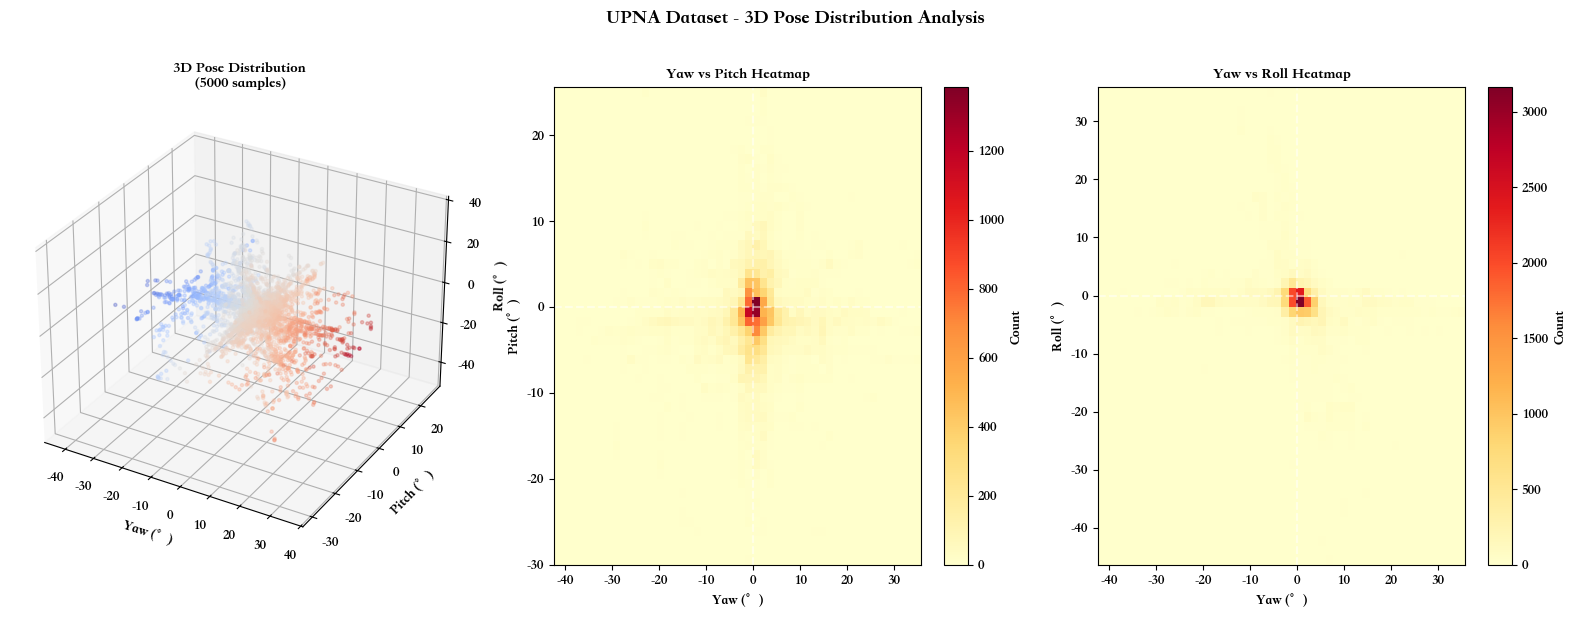


图表已保存为 upna_3d_pose_distribution.png


In [11]:
# 3D可视化姿态分布
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(16, 6))

# 3D散点图 - 所有姿态
ax1 = fig.add_subplot(131, projection='3d')
# 随机采样以避免过度绘制
sample_idx = np.random.choice(len(rolls), min(5000, len(rolls)), replace=False)
scatter = ax1.scatter(yaws[sample_idx], pitches[sample_idx], rolls[sample_idx], 
                       c=yaws[sample_idx], cmap='coolwarm', alpha=0.3, s=5)
ax1.set_xlabel('Yaw (°)')
ax1.set_ylabel('Pitch (°)')
ax1.set_zlabel('Roll (°)')
ax1.set_title('3D Pose Distribution\n(5000 samples)', fontsize=11, fontweight='bold')

# 2D热力图 - Yaw vs Pitch
ax2 = fig.add_subplot(132)
h = ax2.hist2d(yaws, pitches, bins=50, cmap='YlOrRd')
plt.colorbar(h[3], ax=ax2, label='Count')
ax2.set_xlabel('Yaw (°)')
ax2.set_ylabel('Pitch (°)')
ax2.set_title('Yaw vs Pitch Heatmap', fontsize=11, fontweight='bold')
ax2.axhline(y=0, color='white', linestyle='--', alpha=0.5)
ax2.axvline(x=0, color='white', linestyle='--', alpha=0.5)

# 2D热力图 - Yaw vs Roll
ax3 = fig.add_subplot(133)
h = ax3.hist2d(yaws, rolls, bins=50, cmap='YlOrRd')
plt.colorbar(h[3], ax=ax3, label='Count')
ax3.set_xlabel('Yaw (°)')
ax3.set_ylabel('Roll (°)')
ax3.set_title('Yaw vs Roll Heatmap', fontsize=11, fontweight='bold')
ax3.axhline(y=0, color='white', linestyle='--', alpha=0.5)
ax3.axvline(x=0, color='white', linestyle='--', alpha=0.5)

plt.suptitle('UPNA Dataset - 3D Pose Distribution Analysis', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('upna_3d_pose_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n图表已保存为 upna_3d_pose_distribution.png")


## 11. 视频信息分析


In [12]:
# 分析视频基本信息
print("=" * 60)
print("视频文件分析")
print("=" * 60)

# 选择一个视频进行详细分析
sample_video = os.path.join(DATASET_ROOT, "User_01", "user_01_video_01.mp4")

if os.path.exists(sample_video):
    cap = cv2.VideoCapture(sample_video)
    
    # 获取视频属性
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    fps = cap.get(cv2.CAP_PROP_FPS)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration = total_frames / fps if fps > 0 else 0
    
    print(f"\n示例视频: {os.path.basename(sample_video)}")
    print(f"  分辨率: {width} x {height}")
    print(f"  帧率: {fps:.2f} FPS")
    print(f"  总帧数: {total_frames}")
    print(f"  时长: {duration:.2f} 秒")
    
    cap.release()
    
    # 统计所有视频
    print("\n所有视频统计:")
    all_videos = []
    for user_dir in user_dirs:
        user_path = os.path.join(DATASET_ROOT, user_dir)
        videos = glob.glob(os.path.join(user_path, "*.mp4"))
        all_videos.extend(videos)
    
    total_size = sum(os.path.getsize(v) for v in all_videos) / (1024 * 1024 * 1024)  # GB
    print(f"  视频总数: {len(all_videos)}")
    print(f"  总存储空间: {total_size:.2f} GB")
    print(f"  估计总时长: {len(all_videos) * duration / 60:.1f} 分钟")
else:
    print(f"视频文件不存在: {sample_video}")


视频文件分析

示例视频: user_01_video_01.mp4
  分辨率: 1280 x 720
  帧率: 30.00 FPS
  总帧数: 300
  时长: 10.00 秒

所有视频统计:
  视频总数: 120
  总存储空间: 0.09 GB
  估计总时长: 20.0 分钟


## 12. 姿态坐标轴可视化 (RPY Axes)

在人脸上绘制3D姿态坐标轴，直观展示Roll/Pitch/Yaw角度：
- **红色 (X轴)**: Roll方向 - 指向右侧
- **绿色 (Y轴)**: Pitch方向 - 指向下方  
- **蓝色 (Z轴)**: Yaw方向 - 指向前方（从脸部射出）


In [13]:
def draw_pose_axes(img, roll, yaw, pitch, center_x, center_y, axis_length=80, thickness=3):
    """
    在图像上绘制头部姿态的3D坐标轴
    
    Args:
        img: BGR/RGB图像
        roll, yaw, pitch: 欧拉角 (degrees)
        center_x, center_y: 坐标轴原点在图像中的位置
        axis_length: 坐标轴长度 (pixels)
        thickness: 线条粗细
    
    Returns:
        绘制了坐标轴的图像
    """
    img_draw = img.copy()
    
    # 将角度转换为弧度
    roll_rad = np.radians(roll)
    yaw_rad = np.radians(yaw)
    pitch_rad = np.radians(pitch)
    
    # 构建旋转矩阵 (ZYX顺序: yaw -> pitch -> roll)
    # Rotation around Z-axis (Yaw)
    Rz = np.array([
        [np.cos(yaw_rad), -np.sin(yaw_rad), 0],
        [np.sin(yaw_rad), np.cos(yaw_rad), 0],
        [0, 0, 1]
    ])
    
    # Rotation around Y-axis (Pitch)
    Ry = np.array([
        [np.cos(pitch_rad), 0, np.sin(pitch_rad)],
        [0, 1, 0],
        [-np.sin(pitch_rad), 0, np.cos(pitch_rad)]
    ])
    
    # Rotation around X-axis (Roll)
    Rx = np.array([
        [1, 0, 0],
        [0, np.cos(roll_rad), -np.sin(roll_rad)],
        [0, np.sin(roll_rad), np.cos(roll_rad)]
    ])
    
    # 组合旋转矩阵
    R = Rz @ Ry @ Rx
    
    # 定义3D坐标轴端点
    axis_3d = np.array([
        [axis_length, 0, 0],   # X轴 (红)
        [0, axis_length, 0],   # Y轴 (绿)
        [0, 0, axis_length]    # Z轴 (蓝)
    ], dtype=np.float64)
    
    # 应用旋转
    axis_rotated = (R @ axis_3d.T).T
    
    # 投影到2D (简单正交投影)
    # X轴
    x_end = int(center_x + axis_rotated[0, 0])
    y_end = int(center_y - axis_rotated[0, 1])  # 图像Y轴向下，所以取负
    cv2.arrowedLine(img_draw, (int(center_x), int(center_y)), (x_end, y_end), 
                    (255, 0, 0), thickness, tipLength=0.2)
    cv2.putText(img_draw, 'X', (x_end + 5, y_end), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 0, 0), 2)
    
    # Y轴
    x_end = int(center_x + axis_rotated[1, 0])
    y_end = int(center_y - axis_rotated[1, 1])
    cv2.arrowedLine(img_draw, (int(center_x), int(center_y)), (x_end, y_end), 
                    (0, 255, 0), thickness, tipLength=0.2)
    cv2.putText(img_draw, 'Y', (x_end + 5, y_end), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)
    
    # Z轴
    x_end = int(center_x + axis_rotated[2, 0])
    y_end = int(center_y - axis_rotated[2, 1])
    cv2.arrowedLine(img_draw, (int(center_x), int(center_y)), (x_end, y_end), 
                    (0, 0, 255), thickness, tipLength=0.2)
    cv2.putText(img_draw, 'Z', (x_end + 5, y_end), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 255), 2)
    
    # 绘制原点
    cv2.circle(img_draw, (int(center_x), int(center_y)), 5, (255, 255, 255), -1)
    cv2.circle(img_draw, (int(center_x), int(center_y)), 5, (0, 0, 0), 2)
    
    return img_draw


def draw_frame_with_pose_axes(frame, landmarks, bbox, pose, draw_landmarks=True):
    """
    在帧上绘制关键点、边界框和姿态坐标轴
    
    Args:
        frame: RGB图像
        landmarks: 43个关键点坐标
        bbox: 边界框 [x, y, w, h]
        pose: 姿态数据 [Tx, Ty, Tz, Roll, Yaw, Pitch]
        draw_landmarks: 是否绘制关键点
    """
    frame_draw = frame.copy()
    
    # 绘制边界框
    x, y, w, h = int(bbox[0]), int(bbox[1]), int(bbox[2]), int(bbox[3])
    cv2.rectangle(frame_draw, (x, y), (x+w, y+h), (0, 255, 0), 2)
    
    # 绘制关键点
    if draw_landmarks:
        for lx, ly in landmarks:
            cv2.circle(frame_draw, (int(lx), int(ly)), 2, (0, 255, 255), -1)
    
    # 计算人脸中心作为坐标轴原点 (使用鼻尖附近的关键点)
    # 使用bbox中心或关键点中心
    face_center_x = x + w / 2
    face_center_y = y + h / 2
    
    # 或者使用关键点的中心
    # face_center_x = landmarks[:, 0].mean()
    # face_center_y = landmarks[:, 1].mean()
    
    # 绘制姿态坐标轴
    roll, yaw, pitch = pose[3], pose[4], pose[5]
    frame_draw = draw_pose_axes(frame_draw, roll, yaw, pitch, face_center_x, face_center_y)
    
    return frame_draw


print("=" * 60)
print("姿态坐标轴绘制函数已定义")
print("=" * 60)
print("\n函数说明:")
print("  draw_pose_axes(): 根据RPY角度绘制3D坐标轴")
print("  draw_frame_with_pose_axes(): 综合绘制关键点、bbox和坐标轴")


姿态坐标轴绘制函数已定义

函数说明:
  draw_pose_axes(): 根据RPY角度绘制3D坐标轴
  draw_frame_with_pose_axes(): 综合绘制关键点、bbox和坐标轴


不同姿态的坐标轴可视化


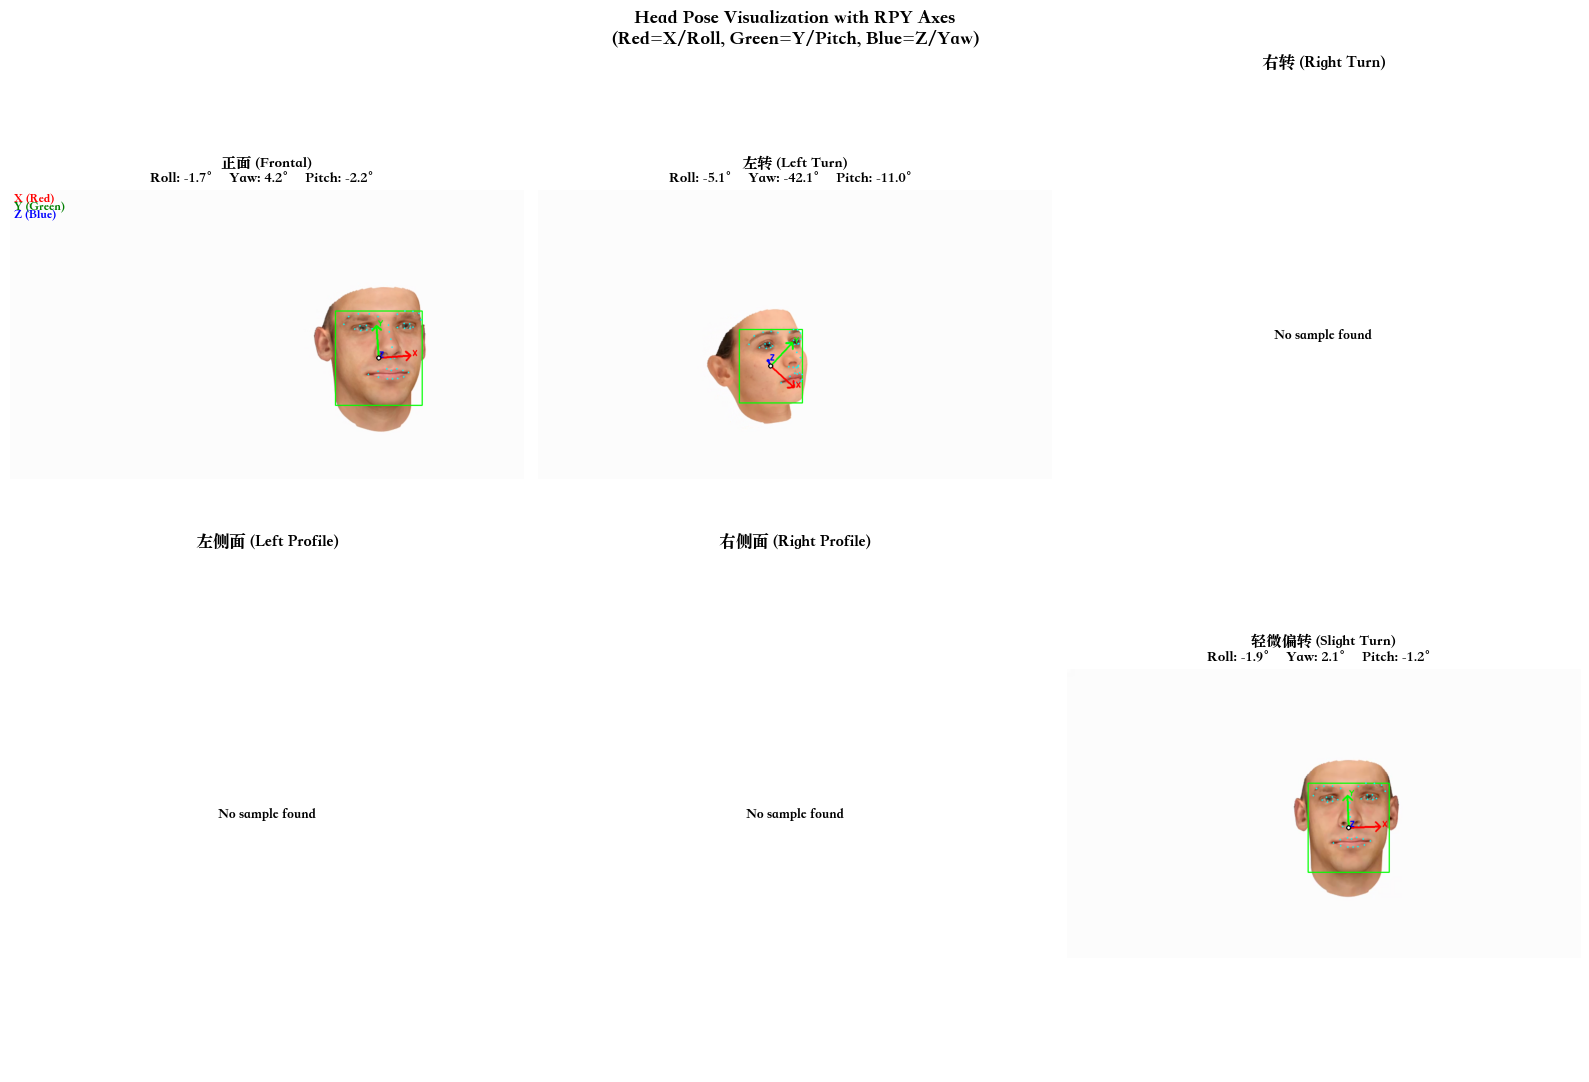


坐标轴说明:
  🔴 红色 X轴: Roll 旋转方向 (歪头)
  🟢 绿色 Y轴: Pitch 旋转方向 (点头)
  🔵 蓝色 Z轴: Yaw 旋转方向 (摇头/视线方向)

图表已保存为 upna_pose_axes_visualization.png


In [14]:
# 可视化不同姿态下的坐标轴
print("=" * 60)
print("不同姿态的坐标轴可视化")
print("=" * 60)

# 定义不同的姿态范围用于采样
pose_samples = [
    {"yaw_range": (-10, 10), "name": "正面 (Frontal)"},
    {"yaw_range": (-60, -40), "name": "左转 (Left Turn)"},
    {"yaw_range": (40, 60), "name": "右转 (Right Turn)"},
    {"yaw_range": (-90, -60), "name": "左侧面 (Left Profile)"},
    {"yaw_range": (60, 90), "name": "右侧面 (Right Profile)"},
    {"yaw_range": (-30, 30), "name": "轻微偏转 (Slight Turn)"},
]

fig, axes = plt.subplots(2, 3, figsize=(16, 11))
axes = axes.flatten()

np.random.seed(123)

for idx, sample_info in enumerate(pose_samples):
    yaw_min, yaw_max = sample_info["yaw_range"]
    title = sample_info["name"]
    
    samples = find_samples_by_yaw_range(DATASET_ROOT, yaw_min, yaw_max, max_samples=1)
    
    if samples:
        sample = samples[0]
        try:
            frame = extract_frame_from_video(sample['video_path'], sample['frame_idx'])
            landmarks = parse_groundtruth_2d(sample['gt2d_path'])[sample['frame_idx']]
            bbox = parse_bbox(sample['bbox_path'])[sample['frame_idx']]
            pose = sample['pose']
            
            if frame is not None:
                # 绘制带坐标轴的帧
                frame_with_axes = draw_frame_with_pose_axes(frame, landmarks, bbox, pose)
                
                axes[idx].imshow(frame_with_axes)
                axes[idx].set_title(
                    f'{title}\n'
                    f'Roll: {pose[3]:.1f}°  Yaw: {pose[4]:.1f}°  Pitch: {pose[5]:.1f}°',
                    fontsize=11, fontweight='bold'
                )
                axes[idx].axis('off')
                
                # 添加图例说明
                if idx == 0:
                    axes[idx].text(10, 30, 'X (Red)', color='red', fontsize=9, fontweight='bold')
                    axes[idx].text(10, 50, 'Y (Green)', color='green', fontsize=9, fontweight='bold')
                    axes[idx].text(10, 70, 'Z (Blue)', color='blue', fontsize=9, fontweight='bold')
            else:
                axes[idx].text(0.5, 0.5, 'Frame not available', ha='center', va='center')
                axes[idx].set_title(title)
                axes[idx].axis('off')
        except Exception as e:
            axes[idx].text(0.5, 0.5, f'Error: {e}', ha='center', va='center', fontsize=8)
            axes[idx].set_title(title)
            axes[idx].axis('off')
    else:
        axes[idx].text(0.5, 0.5, 'No sample found', ha='center', va='center')
        axes[idx].set_title(title)
        axes[idx].axis('off')

plt.suptitle('Head Pose Visualization with RPY Axes\n(Red=X/Roll, Green=Y/Pitch, Blue=Z/Yaw)', 
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('upna_pose_axes_visualization.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n坐标轴说明:")
print("  🔴 红色 X轴: Roll 旋转方向 (歪头)")
print("  🟢 绿色 Y轴: Pitch 旋转方向 (点头)")
print("  🔵 蓝色 Z轴: Yaw 旋转方向 (摇头/视线方向)")
print("\n图表已保存为 upna_pose_axes_visualization.png")


不同Pitch角度的坐标轴可视化


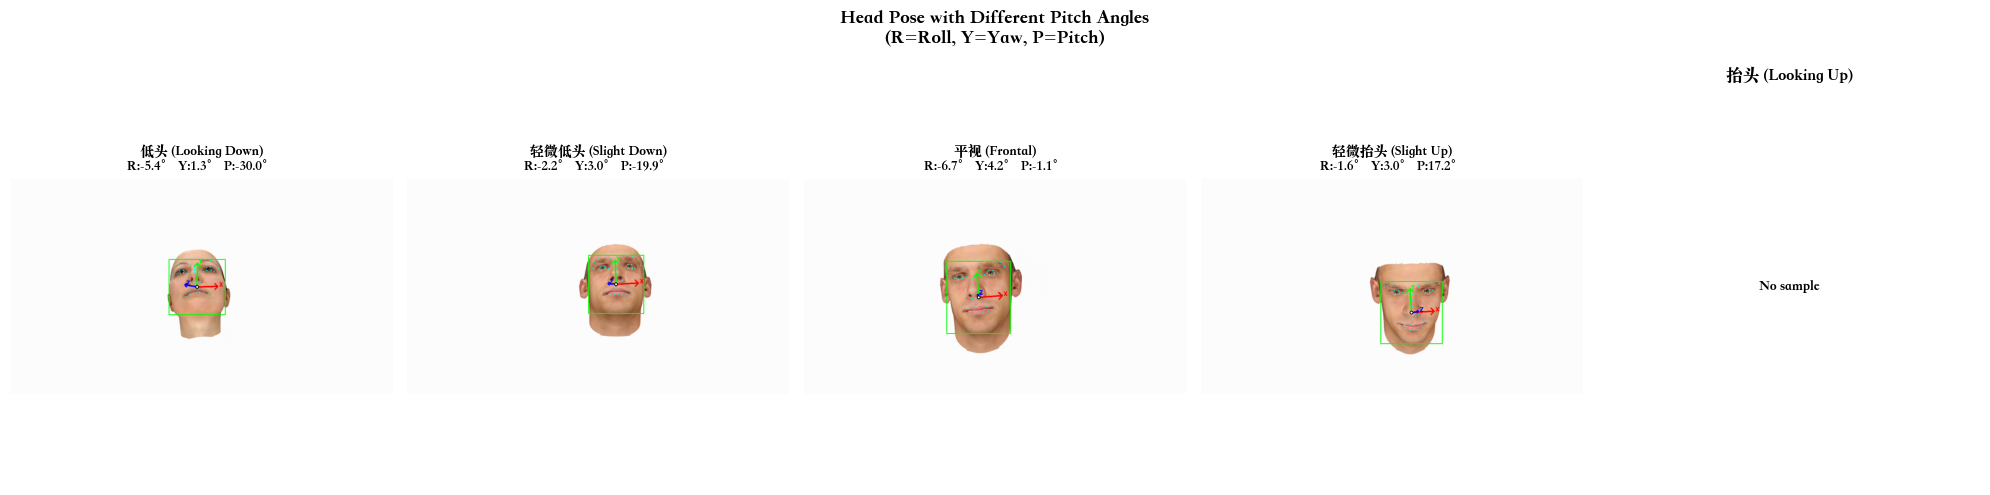


图表已保存为 upna_pitch_samples.png


In [15]:
# 按Pitch角度范围采样展示
def find_samples_by_pitch_range(dataset_root, pitch_min, pitch_max, max_samples=3):
    """找到指定Pitch范围内的样本"""
    samples = []
    user_dirs = sorted([d for d in os.listdir(dataset_root) if d.startswith("User_")])
    
    for user_dir in user_dirs:
        if len(samples) >= max_samples:
            break
            
        user_path = os.path.join(dataset_root, user_dir)
        gt3d_files = sorted(glob.glob(os.path.join(user_path, "*_groundtruth3D.txt")))
        
        for gt3d_file in gt3d_files:
            if len(samples) >= max_samples:
                break
                
            try:
                poses = parse_groundtruth_3d(gt3d_file)
                video_name = os.path.basename(gt3d_file).replace("_groundtruth3D.txt", "")
                video_path = os.path.join(user_path, f"{video_name}.mp4")
                gt2d_path = os.path.join(user_path, f"{video_name}_groundtruth2D.txt")
                bbox_path = os.path.join(user_path, f"{video_name}_bbox.txt")
                
                if not all(os.path.exists(p) for p in [video_path, gt2d_path, bbox_path]):
                    continue
                
                # 找到符合条件的帧 (Pitch在第5列，索引5)
                pitches_arr = poses[:, 5]
                valid_frames = np.where((pitches_arr >= pitch_min) & (pitches_arr <= pitch_max))[0]
                
                if len(valid_frames) > 0:
                    frame_idx = np.random.choice(valid_frames)
                    samples.append({
                        'video_path': video_path,
                        'gt2d_path': gt2d_path,
                        'bbox_path': bbox_path,
                        'frame_idx': frame_idx,
                        'pose': poses[frame_idx],
                        'user': user_dir
                    })
            except:
                pass
    
    return samples


print("=" * 60)
print("不同Pitch角度的坐标轴可视化")
print("=" * 60)

# 定义不同的Pitch范围
pitch_ranges = [
    (-50, -30, "低头 (Looking Down)"),
    (-30, -10, "轻微低头 (Slight Down)"),
    (-10, 10, "平视 (Frontal)"),
    (10, 30, "轻微抬头 (Slight Up)"),
    (30, 50, "抬头 (Looking Up)"),
]

fig, axes = plt.subplots(1, 5, figsize=(20, 5))
np.random.seed(456)

for idx, (pitch_min, pitch_max, title) in enumerate(pitch_ranges):
    samples = find_samples_by_pitch_range(DATASET_ROOT, pitch_min, pitch_max, max_samples=1)
    
    if samples:
        sample = samples[0]
        try:
            frame = extract_frame_from_video(sample['video_path'], sample['frame_idx'])
            landmarks = parse_groundtruth_2d(sample['gt2d_path'])[sample['frame_idx']]
            bbox = parse_bbox(sample['bbox_path'])[sample['frame_idx']]
            pose = sample['pose']
            
            if frame is not None:
                frame_with_axes = draw_frame_with_pose_axes(frame, landmarks, bbox, pose)
                
                axes[idx].imshow(frame_with_axes)
                axes[idx].set_title(
                    f'{title}\n'
                    f'R:{pose[3]:.1f}° Y:{pose[4]:.1f}° P:{pose[5]:.1f}°',
                    fontsize=10, fontweight='bold'
                )
                axes[idx].axis('off')
            else:
                axes[idx].text(0.5, 0.5, 'N/A', ha='center', va='center')
                axes[idx].set_title(title)
                axes[idx].axis('off')
        except Exception as e:
            axes[idx].text(0.5, 0.5, f'Error', ha='center', va='center')
            axes[idx].set_title(title)
            axes[idx].axis('off')
    else:
        axes[idx].text(0.5, 0.5, 'No sample', ha='center', va='center')
        axes[idx].set_title(title)
        axes[idx].axis('off')

plt.suptitle('Head Pose with Different Pitch Angles\n(R=Roll, Y=Yaw, P=Pitch)', 
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('upna_pitch_samples.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n图表已保存为 upna_pitch_samples.png")
